# Factor-momentum horse race

This notebook compares factor momentum constructed from original and volatility-timed factors, portfolio-level volatility timing of factor momentum, and the combination of both timing layers. Its purpose is strategy selection. All reported t-statistics use monthly Newey–West standard errors with 12 lags.

In [1]:
# 0. Libraries and project modules
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

from config import (
    FACTOR_MOMENTUM_PANEL, HAC_LAGS, MANAGED_FACTORS,
)
from factor_momentum_horse_race import (
    COMPACT_SINGLE_LAYER_LABELS, SINGLE_LAYER_STRATEGIES, double_timing_table,
    matched_one_over_n_spanning_table, momentum_spanning_table,
    pairwise_strategy_spanning,
    prepare_factor_momentum_horse_race, strategy_performance_table,
)
from plots import (
    plot_double_timing_heatmap, plot_pairwise_spanning_heatmap,
)
from utils import format_estimate_with_t

## 1. Definitions and common sample

- **Factor momentum:** original factors → factor momentum.
- **Volatility-timed factor momentum:** factor momentum → volatility timing.
- **Factor momentum from volatility-timed factors:** factor volatility timing → factor momentum.
- **Volatility-timed factor momentum from volatility-timed factors:** factor volatility timing → factor momentum → volatility timing.

Factor-momentum signals use the sign of the arithmetic average return over months t−12 through t−1, with no skip month, and equal-weight all available signed positions among Mkt, SMB, HML, Mom, RMW, and CMA. A factor receives no position until 12 non-missing past monthly returns exist, so the available cross-section can change early in the sample. The horse race uses one sample shared by all 16 original, single-timed, and double-timed factor-momentum strategies. Return magnitudes are rescaled ex post to the volatility of original factor momentum over this common sample. This makes gross performance comparable but is not an implementable target-volatility rule.

In [2]:
# 1. Load and validate the common horse-race panel
strategies = pd.read_parquet(FACTOR_MOMENTUM_PANEL)
managed_factors = pd.read_parquet(MANAGED_FACTORS)
analysis = prepare_factor_momentum_horse_race(
    strategies, managed_factors
)
ff5_sample = analysis.dropna(
    subset=['ff5_mkt_rf', 'ff5_smb', 'ff5_hml', 'rmw', 'cma']
)
print(
    f"Common strategy sample: {analysis.date.min():%Y-%m} to "
    f"{analysis.date.max():%Y-%m} ({len(analysis):,} months)."
)
print(
    f"FF5-based alpha sample: {ff5_sample.date.min():%Y-%m} to "
    f"{ff5_sample.date.max():%Y-%m} ({len(ff5_sample):,} months)."
)

Common strategy sample: 1947-07 to 2026-07 (949 months).
FF5-based alpha sample: 1963-07 to 2026-07 (757 months).


In [3]:
# Table formatting is provided by src/utils.py.

## 2. Single-layer performance horse race

The seven candidates comprise original factor momentum, three volatility-timed factor-momentum portfolios, and three factor-momentum portfolios constructed from volatility-timed factors. Mean, standard deviation, and alphas are monthly percentages; the Sharpe ratio is annualized.

In [4]:
single_layer_performance = strategy_performance_table(
    analysis, SINGLE_LAYER_STRATEGIES, HAC_LAGS
)
single_layer_display = pd.DataFrame({
    'Strategy': single_layer_performance['strategy'],
    'Monthly mean (%) [NW t]': format_estimate_with_t(
        single_layer_performance, 'mean_monthly_pct', 'mean_t_nw12'),
    'Monthly std (%)': single_layer_performance['std_monthly_pct'].map(
        lambda x: f'{x:.3f}'),
    'Annualized SR': single_layer_performance['annualized_sharpe'].map(
        lambda x: f'{x:.3f}'),
    'Monthly CAPM alpha (%) [NW t]': format_estimate_with_t(
        single_layer_performance, 'capm_alpha_monthly_pct', 'capm_alpha_t_nw12'),
    'Monthly FF3 alpha (%) [NW t]': format_estimate_with_t(
        single_layer_performance, 'ff3_alpha_monthly_pct', 'ff3_alpha_t_nw12'),
    'Monthly FF5 alpha (%) [NW t]': format_estimate_with_t(
        single_layer_performance, 'ff5_alpha_monthly_pct', 'ff5_alpha_t_nw12'),
    'Monthly FF5 + Mom alpha (%) [NW t]': format_estimate_with_t(
        single_layer_performance, 'ff5_mom_alpha_monthly_pct',
        'ff5_mom_alpha_t_nw12'),
})
display(single_layer_display)

,Strategy,Monthly mean (%) [NW t],Monthly std (%),Annualized SR,Monthly CAPM alpha (%) [NW t],Monthly FF3 alpha (%) [NW t],Monthly FF5 alpha (%) [NW t],Monthly FF5 + Mom alpha (%) [NW t]
0,Factor momentum,0.333 (6.88),1.781,0.647,0.327 (6.04),0.335 (6.20),0.310 (4.11),0.057 (1.22)
1,Lagged RV volatility-timed factor momentum,0.393 (5.99),1.781,0.765,0.354 (5.36),0.332 (5.51),0.353 (4.61),0.242 (3.59)
2,AR(1) volatility-timed factor momentum,0.432 (7.13),1.781,0.841,0.389 (6.19),0.371 (6.38),0.393 (5.26),0.235 (3.61)
3,"GARCH(1,1) volatility-timed factor momentum",0.426 (7.84),1.781,0.829,0.376 (6.50),0.357 (6.59),0.367 (5.35),0.196 (3.08)
4,Factor momentum from lagged-RV-timed factors,0.422 (6.79),1.781,0.821,0.385 (6.22),0.379 (6.19),0.338 (5.20),0.209 (3.82)
5,Factor momentum from AR(1)-timed factors,0.438 (6.54),1.781,0.851,0.416 (5.93),0.408 (5.97),0.372 (4.49),0.212 (3.19)
6,Factor momentum from GARCH-timed factors,0.437 (7.12),1.781,0.850,0.415 (6.29),0.403 (6.37),0.370 (4.78),0.207 (3.29)


## 3. Does factor momentum add to matched 1/N factor portfolios?

Each factor-momentum parent is compared with a long-only 1/N portfolio formed from exactly the same factor inputs: original, lagged-RV-timed, AR(1)-timed, or GARCH-timed factors. These regressions isolate the signed factor-momentum rule relative to passive equal weighting within each input family. The separate portfolio-level volatility-timing step is assessed against its factor-momentum parent later in this notebook.

In [5]:
matched_one_over_n = matched_one_over_n_spanning_table(
    analysis, managed_factors, HAC_LAGS
)
matched_one_over_n_display = pd.DataFrame({
    'Factor inputs': matched_one_over_n['factor_inputs'],
    'Factor-momentum SR': matched_one_over_n['factor_momentum_sharpe'].map(
        lambda x: f'{x:.3f}'),
    '1/N SR': matched_one_over_n['one_over_n_sharpe'].map(lambda x: f'{x:.3f}'),
    'Alpha on matched 1/N (NW t)': format_estimate_with_t(
        matched_one_over_n, 'alpha_monthly_pct', 'alpha_t_nw12'),
    '1/N loading (NW t)': format_estimate_with_t(
        matched_one_over_n, 'one_over_n_loading', 'loading_t_nw12'),
    'R²': matched_one_over_n['r_squared'].map(lambda x: f'{x:.3f}'),
})
display(matched_one_over_n_display)

,Factor inputs,Factor-momentum SR,1/N SR,Alpha on matched 1/N (NW t),1/N loading (NW t),R²
0,Original factors,0.647,1.195,0.058 (1.02),0.446 (8.77),0.199
1,Lagged-RV-timed factors,0.821,1.143,0.116 (1.97),0.521 (7.95),0.271
2,AR(1)-timed factors,0.851,1.118,0.151 (2.34),0.499 (7.36),0.249
3,GARCH-timed factors,0.850,1.167,0.150 (2.65),0.478 (8.47),0.229


## 4. Spanning by momentum and by other factor-momentum strategies

The first table distinguishes spanning by the standalone momentum factor from the stricter FF5 + Mom model. The heatmaps then report every directional pairwise regression among the seven single-layer candidates. A cell uses the row strategy as the dependent return and the column strategy as the spanning return. The 42 pairwise tests are exploratory and should not be read as independently confirmatory tests.

In [6]:
momentum_spanning = momentum_spanning_table(
    analysis, SINGLE_LAYER_STRATEGIES, HAC_LAGS
)
momentum_spanning_display = pd.DataFrame({
    'Strategy': momentum_spanning['strategy'],
    'Mom alpha (NW t)': format_estimate_with_t(
        momentum_spanning, 'momentum_alpha_monthly_pct', 'momentum_alpha_t_nw12'),
    'Mom loading (NW t)': format_estimate_with_t(
        momentum_spanning, 'momentum_loading', 'momentum_loading_t_nw12'),
    'Mom R²': momentum_spanning['momentum_r_squared'].map(lambda x: f'{x:.3f}'),
    'FF5 + Mom alpha (NW t)': format_estimate_with_t(
        momentum_spanning, 'ff5_mom_alpha_monthly_pct', 'ff5_mom_alpha_t_nw12'),
    'FF5 + Mom R²': momentum_spanning['ff5_mom_r_squared'].map(
        lambda x: f'{x:.3f}'),
})
display(momentum_spanning_display)

,Strategy,Mom alpha (NW t),Mom loading (NW t),Mom R²,FF5 + Mom alpha (NW t),FF5 + Mom R²
0,Factor momentum,0.112 (2.43),0.334 (12.14),0.535,0.057 (1.22),0.591
1,Lagged RV volatility-timed factor momentum,0.309 (5.22),0.127 (5.31),0.077,0.242 (3.59),0.135
2,AR(1) volatility-timed factor momentum,0.310 (5.61),0.184 (6.67),0.162,0.235 (3.61),0.237
3,"GARCH(1,1) volatility-timed factor momentum",0.295 (5.56),0.198 (6.40),0.188,0.196 (3.08),0.280
4,Factor momentum from lagged-RV-timed factors,0.302 (5.50),0.181 (5.90),0.157,0.209 (3.82),0.223
5,Factor momentum from AR(1)-timed factors,0.295 (5.08),0.215 (6.28),0.222,0.212 (3.19),0.269
6,Factor momentum from GARCH-timed factors,0.294 (5.29),0.216 (5.95),0.223,0.207 (3.29),0.265


,Dependent strategy,Spanning strategy,Alpha (NW t),R²
1,FM,FM → VT-AR1,0.043 (1.24),0.451
2,FM,FM → VT-GARCH,0.021 (0.67),0.534
4,FM,VT-AR1 factors → FM,0.058 (1.55),0.394
5,FM,VT-GARCH factors → FM,0.045 (1.24),0.433
7,FM → VT-LRV,FM → VT-AR1,-0.019 (-1.37),0.912
20,FM → VT-GARCH,FM → VT-AR1,0.026 (1.36),0.856
28,VT-LRV factors → FM,VT-AR1 factors → FM,0.016 (0.62),0.859
34,VT-AR1 factors → FM,VT-LRV factors → FM,0.046 (1.82),0.859
35,VT-AR1 factors → FM,VT-GARCH factors → FM,0.050 (1.90),0.785
41,VT-GARCH factors → FM,VT-AR1 factors → FM,0.049 (1.83),0.785


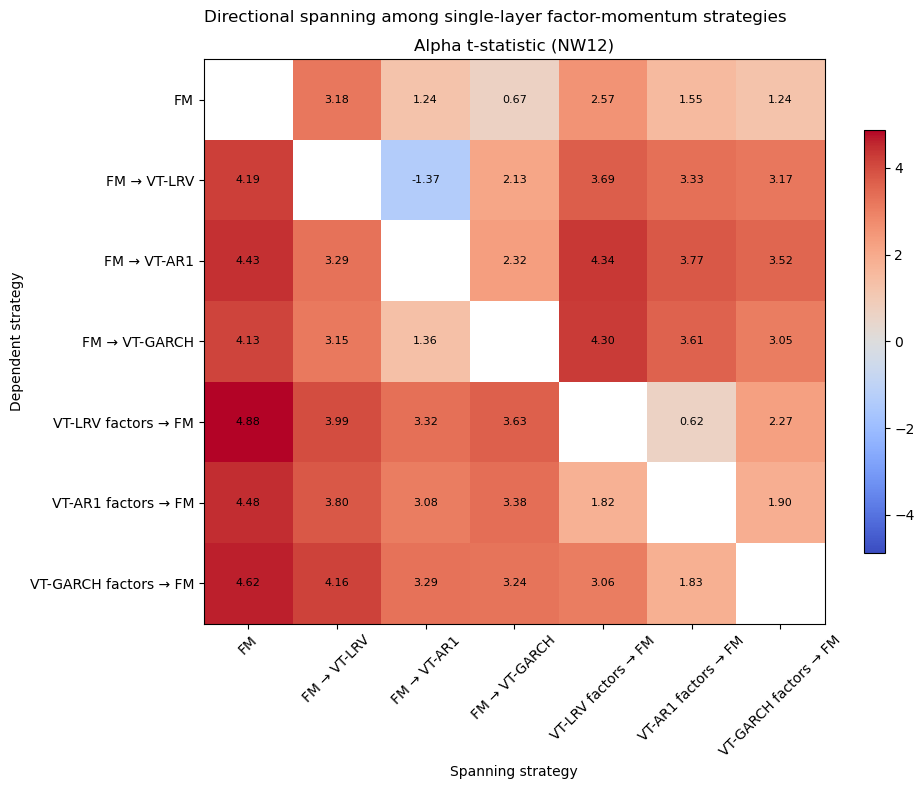

In [7]:
pairwise_spanning = pairwise_strategy_spanning(
    analysis, SINGLE_LAYER_STRATEGIES, HAC_LAGS
)
short_order = list(COMPACT_SINGLE_LAYER_LABELS.values())
alpha_t_matrix = pairwise_spanning.pivot(
    index='dependent_short', columns='spanning_short', values='alpha_t_nw12'
).reindex(index=short_order, columns=short_order)
plot_pairwise_spanning_heatmap(alpha_t_matrix);

not_rejected = pairwise_spanning.loc[
    pairwise_spanning['alpha_t_nw12'].abs().le(1.96)
].copy()
not_rejected_display = pd.DataFrame({
    'Dependent strategy': not_rejected['dependent_short'],
    'Spanning strategy': not_rejected['spanning_short'],
    'Alpha (NW t)': format_estimate_with_t(
        not_rejected, 'alpha_monthly_pct', 'alpha_t_nw12'),
    'R²': not_rejected['r_squared'].map(lambda x: f'{x:.3f}'),
})
display(not_rejected_display)

## 5. Volatility-timed factor momentum from volatility-timed factors

The nine double-timed strategies are tested against their corresponding factor-momentum parent constructed from volatility-timed factors. Incremental alpha therefore measures what the second, portfolio-level timing layer adds. FF5 + Mom alpha is shown separately because a double-timed strategy can retain its parent's factor-model alpha without the second layer adding value.

,Factor-level timing,Portfolio-level timing,Parent SR,Double-timed SR,Incremental alpha (NW t),FF5 + Mom alpha (NW t)
0,Lagged RV,Lagged RV,0.821,0.342,0.044 (0.79),0.083 (1.39)
1,Lagged RV,AR(1),0.821,0.767,0.013 (0.49),0.205 (3.78)
2,Lagged RV,"GARCH(1,1)",0.821,0.531,0.024 (0.52),0.144 (2.34)
3,AR(1),Lagged RV,0.851,0.425,0.001 (0.02),0.110 (1.84)
4,AR(1),AR(1),0.851,0.834,0.011 (0.76),0.194 (3.30)
5,AR(1),"GARCH(1,1)",0.851,0.627,0.011 (0.30),0.145 (2.32)
6,"GARCH(1,1)",Lagged RV,0.850,0.296,0.067 (1.33),0.083 (1.93)
7,"GARCH(1,1)",AR(1),0.850,0.871,0.027 (1.90),0.208 (3.66)
8,"GARCH(1,1)","GARCH(1,1)",0.850,0.737,0.043 (1.31),0.196 (3.38)


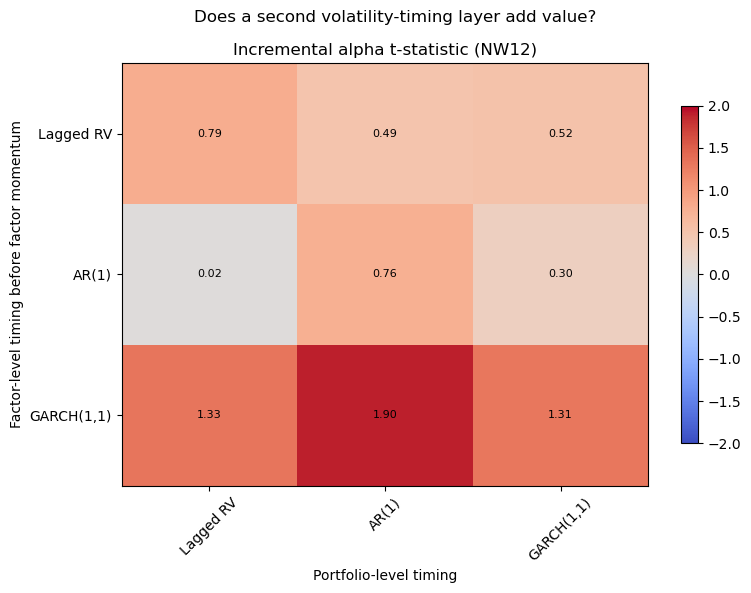

In [8]:
double_timing = double_timing_table(analysis, HAC_LAGS)
double_timing_display = pd.DataFrame({
    'Factor-level timing': double_timing['factor_timing'],
    'Portfolio-level timing': double_timing['portfolio_timing'],
    'Parent SR': double_timing['parent_sharpe'].map(lambda x: f'{x:.3f}'),
    'Double-timed SR': double_timing['strategy_sharpe'].map(lambda x: f'{x:.3f}'),
    'Incremental alpha (NW t)': format_estimate_with_t(
        double_timing, 'incremental_alpha_monthly_pct',
        'incremental_alpha_t_nw12'),
    'FF5 + Mom alpha (NW t)': format_estimate_with_t(
        double_timing, 'ff5_mom_alpha_monthly_pct', 'ff5_mom_alpha_t_nw12'),
})
display(double_timing_display)
incremental_t_matrix = double_timing.pivot(
    index='factor_timing', columns='portfolio_timing',
    values='incremental_alpha_t_nw12',
).reindex(index=['Lagged RV', 'AR(1)', 'GARCH(1,1)'],
          columns=['Lagged RV', 'AR(1)', 'GARCH(1,1)'])
plot_double_timing_heatmap(incremental_t_matrix);

## 6. Horse-race conclusions

- Original factor momentum is spanned by the passive 1/N portfolio formed from the same original factors (alpha t = 1.02). The lagged-RV version is borderline at the conventional 5% threshold (t = 1.97), whereas the AR(1) and GARCH versions retain significant alpha relative to their corresponding timed-factor 1/N portfolios (t = 2.34 and 2.65).
- Original factor momentum has significant alpha relative to standalone momentum, but not relative to FF5 + Mom. All six single-layer volatility-timed constructions retain significant FF5 + Mom alpha.
- Applying volatility timing before or after factor-momentum construction leads to similar Sharpe ratios, but the pairwise regressions show that the resulting returns are generally not interchangeable.
- No double-timed strategy produces incremental alpha significant at 5% relative to its corresponding single-layer parent. Some retain significant FF5 + Mom alpha inherited from the first layer, which is not evidence that the second layer adds value.
- The leading single-layer candidates are therefore the lagged-RV strategies, which stay closest to the published volatility-management design, and the AR(1) strategies, which have the highest gross Sharpe ratios. GARCH produces similar performance but adds model complexity without a clear horse-race advantage. Final selection should also consider native exposure, turnover, and implementability.